# filamentary: the whole pipeline, one stage per section

A folder of GONG H-alpha JPEGs goes in, the submission csv comes out. This notebook runs the four stages that `run.sh` runs,
in the same order with the same options, and stops after each one to show what it produced for one example sun.

Nothing is trained here. The reader's weights are in the repo (`weights/filamentary.pt.aa` to `.ad`) and are loaded below.
The stages are the scripts under `fila/`; the notebook calls them and does not carry a second copy of their code.

| stage | script | in | out |
|---|---|---|---|
| 1 | `fila/suncache.py` | JPEG | nine view planes, disc centred, 2048 px |
| 2 | `fila/add_zscore.py` | nine planes | ten planes (adds the local-contrast plane z) |
| 3 | `fila/unet.py predict` | ten planes + the weights | one probability map per sun |
| 4 | `fila/submit_simple.py` | probability map | non-overlapping filament masks, csv |

Run it from the repository root, top to bottom. Stage 3 wants a GPU (about 1 s per sun on an RTX 5090); set `CPU = True` to run without one (minutes per sun).

In [1]:
import os, sys, hashlib, subprocess, numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from PIL import Image

IMAGES = "MAGFiLO_1.0_Kaggle_2026/test/test_images"   # the folder of JPEGs to segment (the contest's 180 test suns)
WORK   = "run_work/notebook"                            # caches and probability maps go here; safe to delete
OUT    = "submission_notebook.csv"                      # the csv this notebook writes
WEIGHTS = "weights/filamentary.pt"
SEED, GROW, MIN_AREA = 0.99, 0.3, 100                   # the cut the Kaggle entry was made with
CPU  = False                                            # True: predict without a GPU
TILE = None                                             # e.g. 1024: predict in overlapping tiles on a small card
SUBMITTED_SHA256 = "9da51ef202a647af758bc0de502bb1b71bd9f74d24682dbc0a859c5cc9fd1dcb"   # the file uploaded to Kaggle (board 0.37)

assert os.path.isdir("fila") and os.path.isfile("run.sh"), "start Jupyter in the repository root"
assert os.path.isdir(IMAGES), f"no such folder: {IMAGES}"
PY = sys.executable
sys.path.insert(0, "fila")

def sh(*args, tail=6):
    "run one pipeline script exactly as run.sh does; stop the notebook if it fails; show the end of what it printed"
    print("$", " ".join(args))
    r = subprocess.run(args, capture_output=True, text=True)
    lines = [l for l in (r.stdout + r.stderr).replace("\r", "\n").splitlines() if l.strip()]
    print("\n".join(lines[-tail:]))
    if r.returncode: raise RuntimeError(f"{args[1] if len(args) > 1 else args[0]} exited with {r.returncode}")

stems = sorted(f.rsplit(".", 1)[0] for f in os.listdir(IMAGES) if f.lower().endswith((".jpg", ".jpeg")))
PICK = "20120218152654Bh"                              # the sun shown after each stage: it has 7 filaments, the test set's median; any stem works
EXAMPLE = PICK if PICK in stems else stems[0]
print(len(stems), "suns in", IMAGES, "- example sun:", EXAMPLE)

180 suns in MAGFiLO_1.0_Kaggle_2026/test/test_images - example sun: 20120218152654Bh


## The reader's weights

The file is over GitHub's 100 MB limit, so it is committed in four parts. Joining them is a plain `cat`; the checksum proves the
join is the file that was trained. Then the weights are loaded to show what the file says about itself: which encoder, which
planes it reads, and how many numbers it holds.

In [2]:
import glob, torch
if not os.path.isfile(WEIGHTS):
    parts = sorted(glob.glob(WEIGHTS + ".??"))
    with open(WEIGHTS, "wb") as out:
        for p in parts: out.write(open(p, "rb").read())
    print("joined", len(parts), "parts ->", WEIGHTS)
want = open(WEIGHTS + ".sha256").read().split()[0]
h = hashlib.sha256()
with open(WEIGHTS, "rb") as f:
    for block in iter(lambda: f.read(1 << 24), b""): h.update(block)
assert h.hexdigest() == want, "checksum FAILED: the parts are corrupt"
print("checksum ok:", want[:16], "...")

ck = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
n = sum(v.numel() for v in ck["state"].values())
print("encoder:", ck["encoder"], "| planes read:", ck["channels"], "| + 2 coordinate planes:", bool(ck.get("geo", False)), f"| {n / 1e6:.1f} M numbers")
NEEDZ = 9 in ck["channels"]
del ck

joined 4 parts -> weights/filamentary.pt
checksum ok: 76898634c776a474 ...


encoder: tu-convnext_base | planes read: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | + 2 coordinate planes: True | 92.7 M numbers


## Stage 1: one JPEG becomes a stack of view planes

`suncache.py` finds the solar disc, centres it in a 2048 px frame and computes planes that each state one idea about the image:
the raw picture, how much darker a pixel is than its surroundings, local texture, distance from disc centre, and the direction
and order of the chromospheric threads. The README table "The reader" has one line per plane. CPU only; suns already cached are skipped.

In [3]:
sh(PY, "fila/suncache.py", "frames", f"{WORK}/cache", "--dir", IMAGES, "--full", "--comb")
CACHE = f"{WORK}/cache"

$ /home/dwhitteker/venv/bin/python3 fila/suncache.py frames run_work/notebook/cache --dir MAGFiLO_1.0_Kaggle_2026/test/test_images --full --comb


180 frames to cache from MAGFiLO_1.0_Kaggle_2026/test/test_images
-> run_work/notebook/cache


## Stage 2: the local-contrast plane

`add_zscore.py` adds plane 9, z: how far a pixel sits below its 255 px neighbourhood, in units of that neighbourhood's own
texture. A filament three grey levels deep in quiet sun and one fifteen levels deep in an active region read alike on this plane.
It runs only if the reader was trained with it (this one was).

In [4]:
if NEEDZ:
    sh(PY, "fila/add_zscore.py", f"{WORK}/cache", f"{WORK}/cache9"); CACHE = f"{WORK}/cache9"
else: print("this reader has no z plane; stage skipped")

$ /home/dwhitteker/venv/bin/python3 fila/add_zscore.py run_work/notebook/cache run_work/notebook/cache9


50/180  20130206063154Uh.npz (10, 2048, 2048)
100/180  20150623152934Ch.npz (10, 2048, 2048)
150/180  20171122022450Uh.npz (10, 2048, 2048)
180/180  20220728185352Th.npz (10, 2048, 2048)
done: run_work/notebook/cache9


planes: (10, 2048, 2048) | disc shift dx, dy: 0 -1


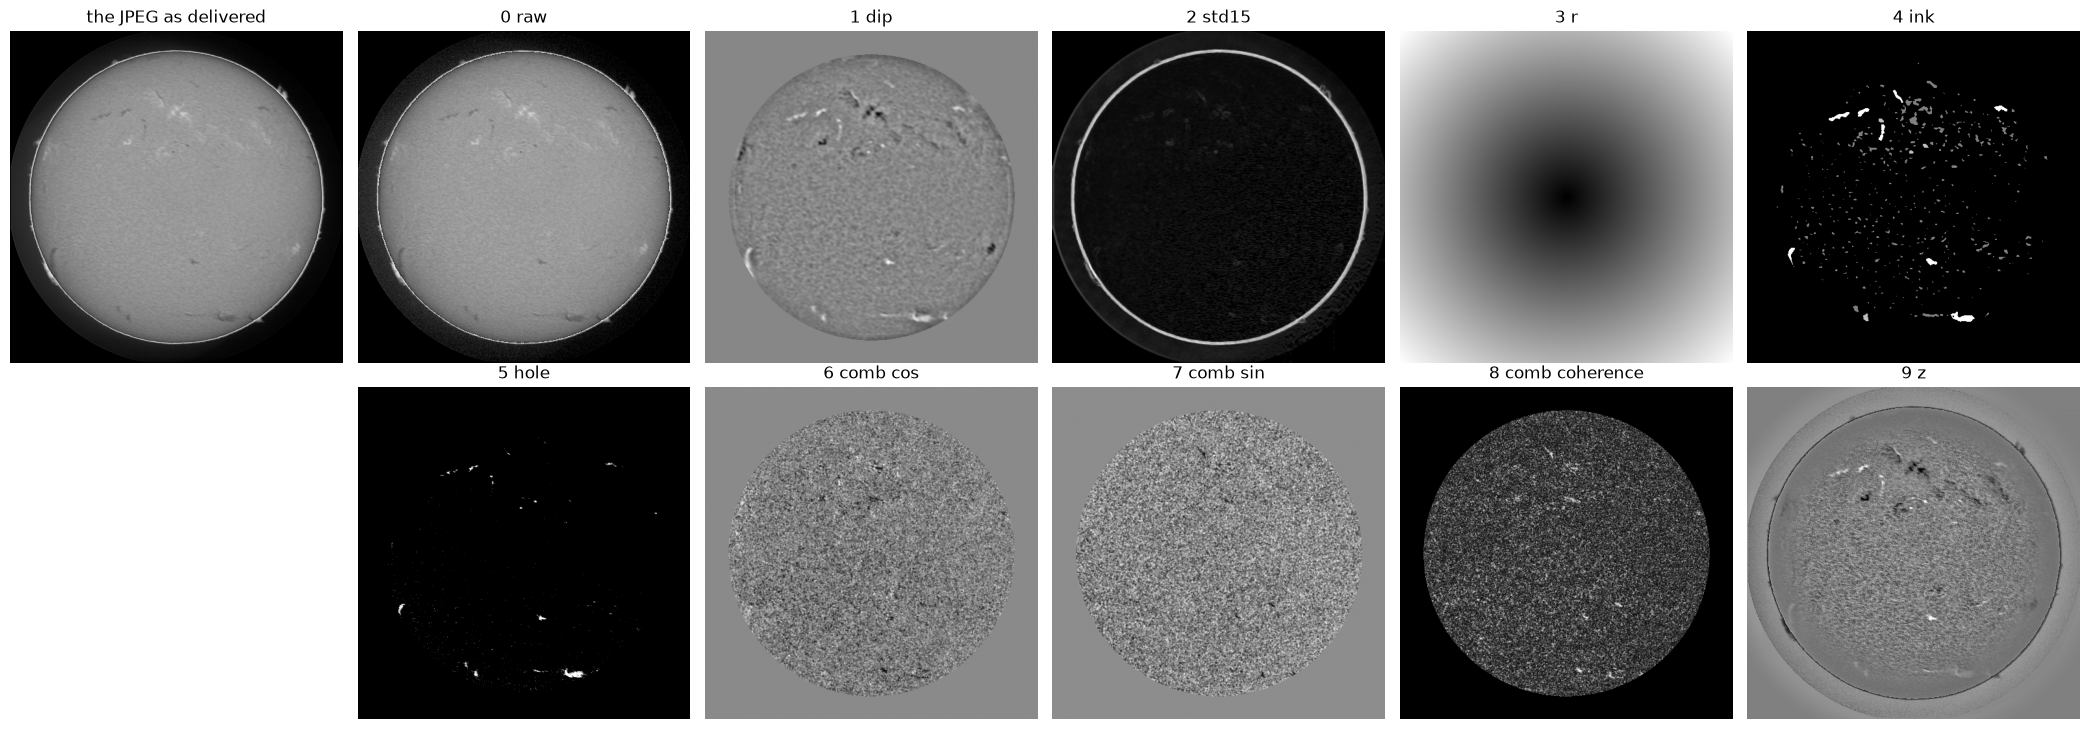

In [5]:
jpg = next(os.path.join(IMAGES, f) for f in os.listdir(IMAGES) if f.startswith(EXAMPLE + "."))
z = np.load(f"{CACHE}/{EXAMPLE}.npz"); views = z["views"].astype(np.float32)
print("planes:", views.shape, "| disc shift dx, dy:", int(z["dx"]), int(z["dy"]))
names = ["0 raw", "1 dip", "2 std15", "3 r", "4 ink", "5 hole", "6 comb cos", "7 comb sin", "8 comb coherence", "9 z"]
fig, ax = plt.subplots(2, 6, figsize=(21, 7.4)); ax = ax.ravel()
ax[0].imshow(Image.open(jpg), cmap="gray"); ax[0].set_title("the JPEG as delivered")
for i in range(views.shape[0]):
    k = i + 1 if i < 5 else i + 2
    ax[k].imshow(views[i][::4, ::4], cmap="gray"); ax[k].set_title(names[i] if i < len(names) else str(i))
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Stage 3: the reader turns the planes into a probability map

`unet.py predict` builds the network (a U-Net decoder on a ConvNeXt-Base encoder), loads the weights from the file above, and
predicts each sun eight times (four rotations, each mirrored) and averages. Each pixel of the result is the reader's
probability that the pixel belongs to a filament. This is the only stage that uses the GPU.

In [6]:
extra = (["--cpu"] if CPU else []) + (["--tile", str(TILE)] if TILE else [])
sh(PY, "fila/unet.py", "predict", CACHE, WEIGHTS, f"{WORK}/prob", "--tta", *extra)

$ /home/dwhitteker/venv/bin/python3 fila/unet.py predict run_work/notebook/cache9 weights/filamentary.pt run_work/notebook/prob --tta


180 prob maps -> run_work/notebook/prob  (0.83 s/sun, TTA x8)


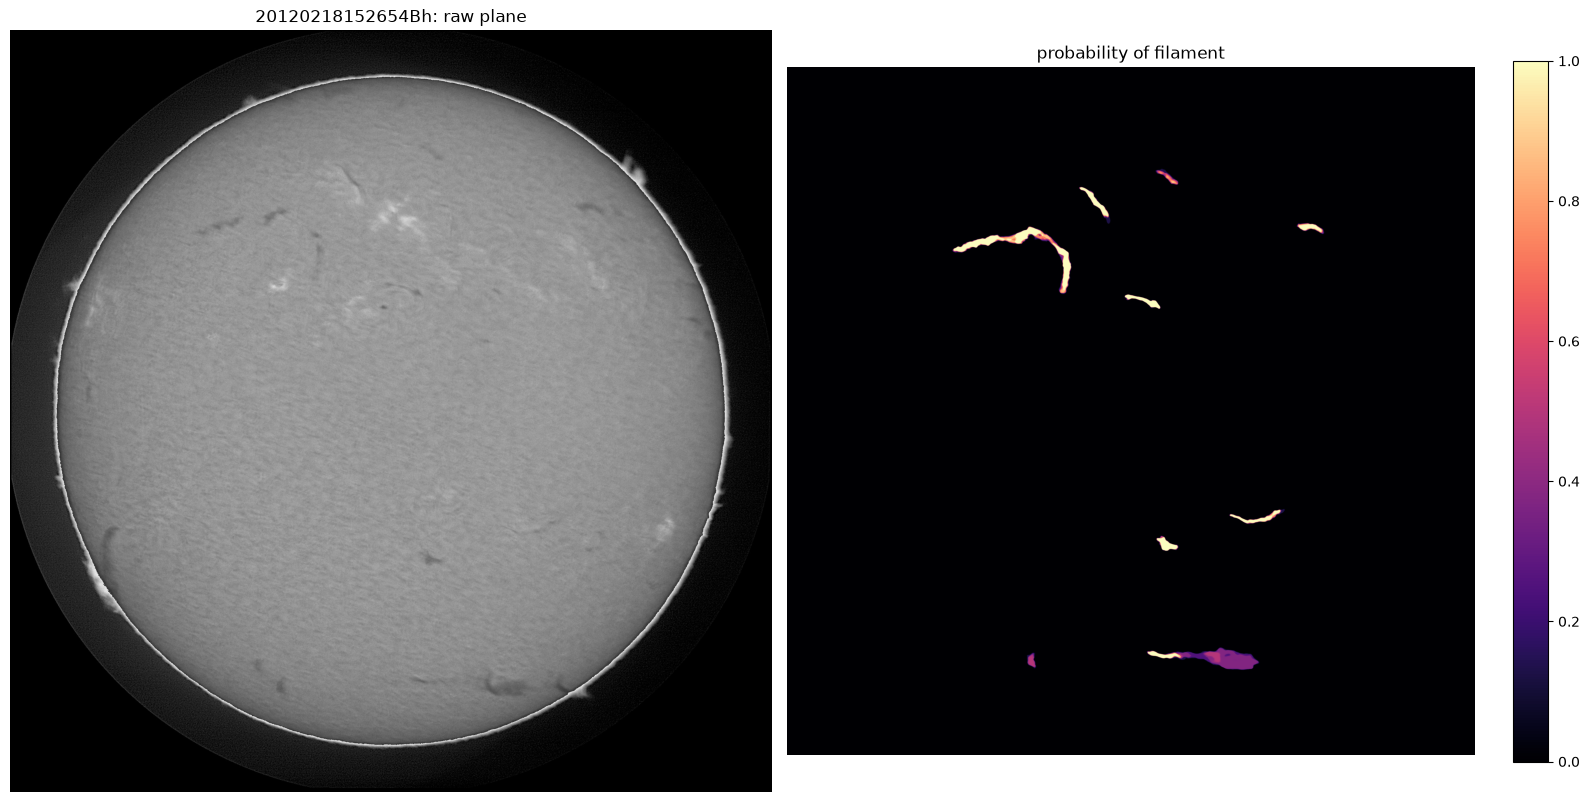

In [7]:
p = np.load(f"{WORK}/prob/{EXAMPLE}.npz"); pm = p["prob"].astype(np.float32); step = 2048 // pm.shape[0]
raw = views[0][::step, ::step]
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(raw, cmap="gray"); ax[0].set_title(f"{EXAMPLE}: raw plane")
im = ax[1].imshow(pm, cmap="magma", vmin=0, vmax=1); ax[1].set_title("probability of filament"); plt.colorbar(im, ax=ax[1], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Stage 4: seed and grow, then the csv

`submit_simple.py` cuts each probability map into separate filaments. A region is every connected patch of pixels above the
grow level (0.3); it is kept only if somewhere inside it the reader was nearly certain (a seed pixel at 0.99 or above) and it
covers at least 100 px. Kept regions are moved back to the original frame, made non-overlapping, and written one per row.

The picture shows the kept regions for the example sun, each in its own colour, cut by the same function the script uses.

In [8]:
sh(PY, "fila/submit_simple.py", f"{WORK}/prob", OUT, "--seed", str(SEED), "--grow", str(GROW), "--min-area", str(MIN_AREA))

$ /home/dwhitteker/venv/bin/python3 fila/submit_simple.py run_work/notebook/prob submission_notebook.csv --seed 0.99 --grow 0.3 --min-area 100


wrote submission_notebook.csv: 180 suns, 1214 filaments (seed 0.99 grow 0.3 min-area 100 min-elong 0.0)


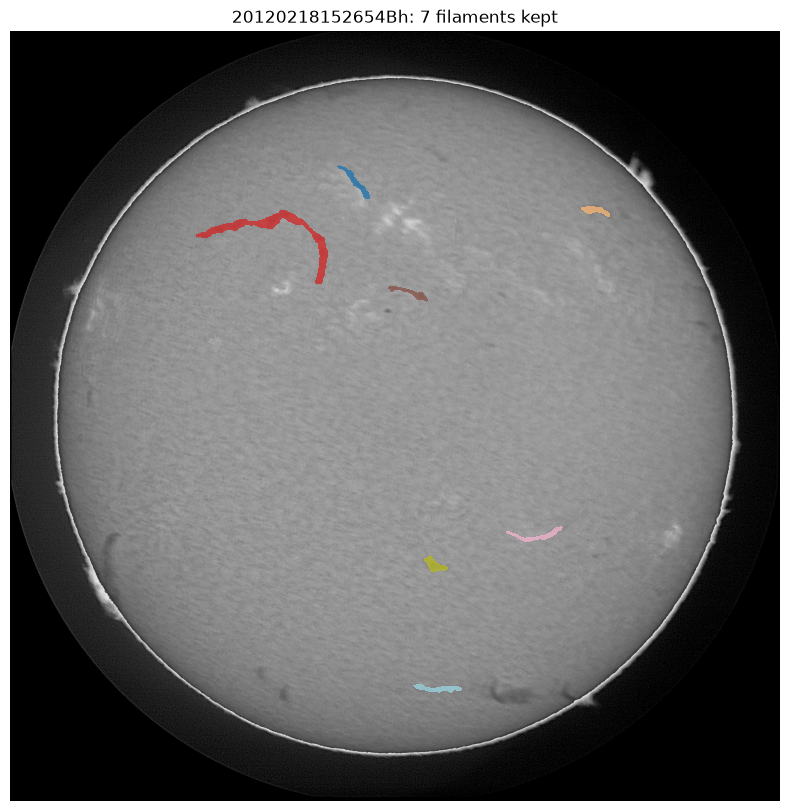

In [9]:
import sun_eye as se
insts = se.cut(pm, SEED, GROW, MIN_AREA, min_elong=0.0)
lab = np.zeros(pm.shape, np.int32)
for i, (y0, x0, c) in enumerate(insts):
    c = np.asarray(c.get() if hasattr(c, "get") else c).astype(bool)
    lab[y0:y0 + c.shape[0], x0:x0 + c.shape[1]][c] = i + 1
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(raw, cmap="gray"); ax.imshow(np.ma.masked_equal(lab, 0), cmap="tab20", alpha=0.75, interpolation="nearest")
ax.set_title(f"{EXAMPLE}: {len(insts)} filaments kept"); ax.axis("off"); plt.show()

## Is it the file that was submitted?

The csv uploaded to Kaggle (public board 0.37) has the SHA-256 recorded at the top of this notebook. If the file written above
has the same hash, the notebook has reproduced the submission byte for byte.

In [10]:
got = hashlib.sha256(open(OUT, "rb").read()).hexdigest(); rows = sum(1 for _ in open(OUT)) - 1
print(f"{OUT}: {rows} filaments on {len(stems)} suns")
print("sha256   ", got); print("submitted", SUBMITTED_SHA256)
print("IDENTICAL to the submitted file" if got == SUBMITTED_SHA256 else "DIFFERS from the submitted file (the submitted file has 1214 filaments on the 180 test suns)")

submission_notebook.csv: 1214 filaments on 180 suns
sha256    9da51ef202a647af758bc0de502bb1b71bd9f74d24682dbc0a859c5cc9fd1dcb
submitted 9da51ef202a647af758bc0de502bb1b71bd9f74d24682dbc0a859c5cc9fd1dcb
IDENTICAL to the submitted file


## Optional: the check against the labelled suns

`bash run.sh --check` sends 50 labelled training suns (`docs/heldout.txt`) through the same four stages and scores them with the
hosts' Panoptic Quality. It needs the contest's training folder beside `fila/`.

For the shipped weights this is a reproduction check and not a held-out score: the shipped reader was trained on all 707 labelled
suns, those 50 included, so the number to expect is PQ 0.5540 (TP 485, FP 127, FN 134). The honest held-out figure, 0.4615, comes
from a twin trained with the same recipe on the other 657 suns; see README "Reproduce the submission".

In [11]:
if os.path.isdir("MAGFiLO_1.0_Kaggle_2026/train/train_images"):
    sh("bash", "run.sh", "--check", "--work", f"{WORK}/check", *extra, tail=8)
else: print("no MAGFiLO_1.0_Kaggle_2026/train folder here; check skipped")

$ bash run.sh --check --work run_work/notebook/check


done: run_work/notebook/check/cache_heldout9
50 prob maps -> run_work/notebook/check/prob_heldout  (0.85 s/sun, TTA x8)
wrote run_work/notebook/check/heldout.csv: 50 suns, 361 filaments (seed 0.99 grow 0.3 min-area 100 min-elong 0.0)
== PQ on docs/heldout.txt: reproduction check -- the shipped reader trained on these suns (expect 0.5540; not a held-out score)
86 annotator-images, 619 GT filaments, 50 distinct images
PQ 0.5540   TP 485  FP 127  FN 134   mean IoU of TPs 0.703   mean Dice (overlapping pairs) 0.767
  GT -> n preds (1:n) {0: 68, 1: 532, 2: 16, 3: 3}
  pred -> n GTs (n:1) {0: 51, 1: 549, 2: 12}
